In [1]:
%pip install numpy matplotlib scipy > /dev/null
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
plt.rcParams["savefig.pad_inches"] = 0.05
import kalman
kalman.set_debug(0)

Note: you may need to restart the kernel to use updated packages.


# Combinatorial Kalman Filter — Track Finding

Most Kalman filters follow one trajectory from a stream of single measurements. A particle
detector poses a harder problem. Each detector layer records many hits: some from real particles,
some from background. Nobody tells the filter which hit belongs to which track.

The Combinatorial Kalman Filter (CKF) solves this by following tracks outward, layer by layer.
It starts from a **seed**, a first guess of a track built from one hit on the innermost layer.
At each further layer it does three things:

1. **Predict** where the track should cross the layer.
2. **Gate and branch.** Every hit close enough to the prediction opens a new candidate track, a
   **branch**. One more branch covers the case where the detector missed the hit, called a
   **hole**.
3. **Prune.** Only the few best candidates are kept, so the tree of branches stays small.

At the end, candidates that share too many hits compete and the best one wins.

Particle trackers such as Belle II's use this algorithm
([BELLE2-PTHESIS-2019-002](https://docs.belle2.org/files/4163/BELLE2-PTHESIS-2019-002/1/BELLE2-PTHESIS-2019-002.pdf)).

This notebook runs the CKF on a simple 2-D tracker, a simplified drift chamber: a charged particle
bends in a uniform magnetic field and leaves one hit on each of eight concentric layers.

## Step 1 — Define the Detector Model

`DriftChamberModel` holds the detector and the particle physics.

The state is $\mathbf{x} = [p_x,\ p_y,\ q_x,\ q_y]$: the position $(p_x, p_y)$ in cm and the
momentum $(q_x, q_y)$ in GeV/c, both in the plane transverse to the field. The field bends the
path into a circle of radius

$$R\,[\text{m}] = \frac{|q|\,[\text{GeV}/c]}{0.3\, B\,[\text{T}]}$$

so a 1 GeV/c particle in a 1.5 T field turns on a circle of radius 2.2 m.

This filter does not step in time. It steps from one layer to the next: the prediction moves the
state along the circle up to the radius of the next layer. A measurement is the position where
the track crosses that layer.

The values below are close to the Belle II drift chamber: a 1.5 T field, layers from 20 cm to
104 cm, and a hit resolution `sigma_hit` (a standard deviation) of 0.013 cm, or 130 µm. Each
layer also receives 10 background hits, and a layer misses a real hit 5% of the time.

In [2]:
from kalman.apps import DriftChamberModel

model = DriftChamberModel(n_layers=8, r_inner=20.0, r_step=12.0, Bz=1.5, sigma_hit=0.013)
event = model.generate_event(n_tracks=3, n_background=10, efficiency=0.95, seed=2)

print(f"layer radii [cm]: {model.radii}")
print(f"true tracks     : {event.n_tracks}")
for layer, hits in enumerate(event.hits):
    n_signal = int((event.truth[layer] >= 0).sum())
    n_background = len(hits) - n_signal
    print(f"  layer {layer}: {len(hits):2d} hits  ({n_signal} signal + {n_background} background)")

layer radii [cm]: [ 20.  32.  44.  56.  68.  80.  92. 104.]
true tracks     : 3
  layer 0: 13 hits  (3 signal + 10 background)
  layer 1: 13 hits  (3 signal + 10 background)
  layer 2: 13 hits  (3 signal + 10 background)
  layer 3: 13 hits  (3 signal + 10 background)
  layer 4: 12 hits  (2 signal + 10 background)
  layer 5: 13 hits  (3 signal + 10 background)
  layer 6: 13 hits  (3 signal + 10 background)
  layer 7: 13 hits  (3 signal + 10 background)


### The Raw Event

Every layer holds a mix of signal and background hits. The colors are for us only: the track
finder sees positions, not which particle made each hit.

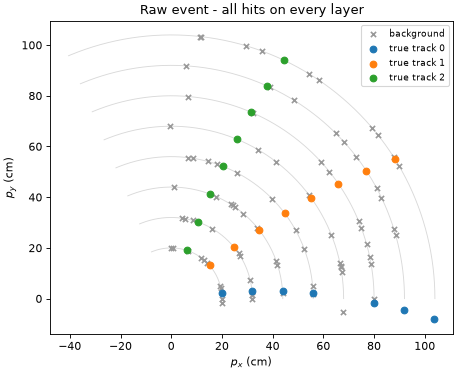

In [3]:
# Layers as thin arcs, signal hits colored by true track, background as grey crosses.
def draw_layers(ax, radii):
    theta = np.linspace(0, np.pi / 2 + 0.4, 200)
    for r in radii:
        ax.plot(r * np.cos(theta), r * np.sin(theta), color="0.85", lw=0.8, zorder=0)

fig, ax = plt.subplots(figsize=(6.5, 6.5))
draw_layers(ax, model.radii)
colors = plt.get_cmap("tab10")
for layer in range(len(event.hits)):
    hits, truth = event.hits[layer], event.truth[layer]
    is_background = truth < 0
    ax.scatter(hits[is_background, 0], hits[is_background, 1], s=22, c="0.6", marker="x",
               zorder=2, label="background" if layer == 0 else None)
    for track_id in range(event.n_tracks):
        mask = truth == track_id
        ax.scatter(hits[mask, 0], hits[mask, 1], s=36, color=colors(track_id), zorder=3,
                   label=f"true track {track_id}" if layer == 0 else None)

ax.set_aspect("equal")
ax.set_xlabel("$p_x$ (cm)")
ax.set_ylabel("$p_y$ (cm)")
ax.set_title("Raw event - all hits on every layer")
ax.legend(fontsize=8, loc="upper right")
plt.show()

## Step 2 — Run the CKF

`CombinatorialKalmanFilter` wraps the model. Its `forward` method takes the hits of every layer
and returns the tracks it found. Four settings control the search:

| Parameter | Value here | Meaning |
|---|---|---|
| `max_candidates` | 6 | How many candidates survive pruning at each layer. More finds more tracks but runs slower. |
| `max_holes` | 2 | How many layers a track may skip. |
| `min_hits` | 6 | Tracks with fewer hits are rejected. Short tracks are easy to build from background alone. |
| `shared_hit_frac` | 0.3 | A candidate is dropped if more than this fraction of its hits belong to a better track. |

The gate uses the innovation $\boldsymbol{\nu}$, the difference between a hit and the predicted
crossing point, and its covariance $\mathbf{S}$. A hit passes if
$\chi^2 = \boldsymbol{\nu}^\top \mathbf{S}^{-1} \boldsymbol{\nu}$ is below `chi2_cut`. The default
9.21 keeps 99% of the true hits for a two-dimensional measurement.

For each track found, the cell prints its **purity**: the fraction of its hits that come from one
and the same true particle.

In [4]:
from kalman.framework.filters import CombinatorialKalmanFilter

ckf = CombinatorialKalmanFilter(model, max_candidates=6, max_holes=2, min_hits=6, shared_hit_frac=0.3)
tracks = ckf.forward(event.hits, layer_radii=event.radii)

print(f"chi2 gate       : {ckf.chi2_cut:.2f}")
print(f"seeds           : {len(event.hits[0])}  (one per hit on the innermost layer)")
print(f"candidates      : {len(ckf.candidates)}  (seeds that grew into a track)")
print(f"accepted tracks : {len(tracks)}\n")
for i, raw in enumerate(ckf.tracks_raw):
    truth_ids = [int(event.truth[layer][hit]) for (layer, hit) in raw.hit_ids]
    signal_ids = [truth_id for truth_id in truth_ids if truth_id >= 0]
    majority_id = max(set(signal_ids), key=signal_ids.count) if signal_ids else -1
    purity = signal_ids.count(majority_id) / len(truth_ids)
    print(f"  track {i}: {raw.n_hits} hits, chi2 per hit={raw.chi2/raw.n_hits:5.2f}, "
          f"true track={majority_id}, purity={purity:4.0%}, holes={raw.holes}")

chi2 gate       : 9.21
seeds           : 13  (one per hit on the innermost layer)
candidates      : 4  (seeds that grew into a track)
accepted tracks : 3

  track 0: 8 hits, chi2 per hit= 0.98, true track=1, purity=100%, holes=0
  track 1: 8 hits, chi2 per hit= 1.20, true track=2, purity=100%, holes=0
  track 2: 7 hits, chi2 per hit= 0.23, true track=0, purity=100%, holes=1


### Reconstructed Tracks

Each found track is drawn as a colored line through the hits it claimed (circled). Hits left grey
were rejected. The printout above says whether each track picked only hits of one true particle,
and the track with a hole is the one that lost a hit to the 5% inefficiency.

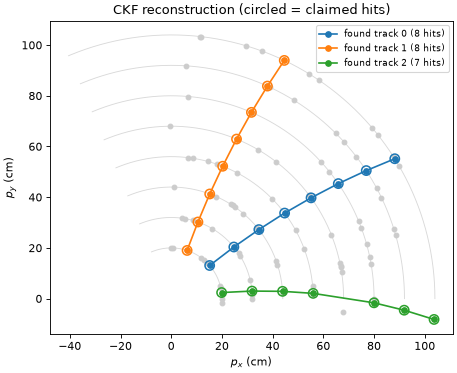

In [5]:
# `tracks` holds one record per found track: its estimated path and the hits it claimed.
fig, ax = plt.subplots(figsize=(6.5, 6.5))
draw_layers(ax, model.radii)

# All hits, drawn faint, as background context.
for layer in range(len(event.hits)):
    hits = event.hits[layer]
    ax.scatter(hits[:, 0], hits[:, 1], s=18, c="0.8", zorder=1)

for i, rec in enumerate(tracks):
    position = rec.xk[:, :2]
    ax.plot(position[:, 0], position[:, 1], "-o", ms=5, color=colors(i), zorder=4,
            label=f"found track {i} ({len(rec)} hits)")
    claimed_hits = rec.zk
    ax.scatter(claimed_hits[:, 0], claimed_hits[:, 1], s=70, facecolors="none",
               edgecolors=colors(i), linewidths=1.4, zorder=3)

ax.set_aspect("equal")
ax.set_xlabel("$p_x$ (cm)")
ax.set_ylabel("$p_y$ (cm)")
ax.set_title("CKF reconstruction (circled = claimed hits)")
ax.legend(fontsize=8, loc="upper right")
plt.show()

## Step 3 — Smooth the Fitted Tracks

During the forward pass, the estimate at a layer only knows the hits up to that layer. On the
innermost layer it is still the seed, whose momentum is a guess of 1 GeV/c with an uncertainty of
1 GeV/c on each component.

`backward()` runs the Rauch–Tung–Striebel (RTS) smoother, which passes the information of the
outer hits back to the inner layers. The momentum at the first layer becomes as well known as at
the last one. The position changes little, because each hit already measures it to 130 µm.

In [6]:
smoothed = ckf.backward()   # uses the forward pass above

def sigma(P, block):
    # Standard deviation of the position (block 0:2) or momentum (block 2:4) part of P.
    return np.sqrt(np.trace(P[block, block]))

pos, mom = slice(0, 2), slice(2, 4)
for i, (filtered_track, smoothed_track) in enumerate(zip(tracks, smoothed)):
    pos_filtered = np.mean([sigma(P, pos) for P in filtered_track.Pk])
    pos_smoothed = np.mean([sigma(P, pos) for P in smoothed_track.Pk])
    print(f"track {i}:")
    print(f"  position sigma, mean over layers  filtered = {1e4 * pos_filtered:4.0f} um      "
          f"smoothed = {1e4 * pos_smoothed:4.0f} um")
    print(f"  momentum sigma, innermost layer   filtered = {sigma(filtered_track.Pk[0], mom):4.2f} GeV/c   "
          f"smoothed = {sigma(smoothed_track.Pk[0], mom):4.2f} GeV/c")
    print(f"  smoothed momentum = {np.hypot(*smoothed_track.xk[0, 2:4].ravel()):.2f} GeV/c")

print("\ntrue momenta [GeV/c]:", np.round([np.hypot(*t[0, 2:]) for t in event.tracks], 2))

track 0:
  position sigma, mean over layers  filtered =  137 um      smoothed =  134 um
  momentum sigma, innermost layer   filtered = 1.41 GeV/c   smoothed = 0.08 GeV/c
  smoothed momentum = 1.21 GeV/c
track 1:
  position sigma, mean over layers  filtered =  136 um      smoothed =  133 um
  momentum sigma, innermost layer   filtered = 1.41 GeV/c   smoothed = 0.10 GeV/c
  smoothed momentum = 1.40 GeV/c
track 2:
  position sigma, mean over layers  filtered =  138 um      smoothed =  136 um
  momentum sigma, innermost layer   filtered = 1.41 GeV/c   smoothed = 0.06 GeV/c
  smoothed momentum = 0.95 GeV/c

true momenta [GeV/c]: [0.94 1.26 1.48]
